# Experiment 20: Probabilistic PCA and Reconstruction Analysis

A smart-factory sensor network measures temperature, vibration, pressure, current and humidity with noise and occasional missing readings. We impute missing values, fit a probabilistic PCA model through scikit-learn PCA, estimate noise variance and generate sensor samples.

**Tools:** NumPy, Pandas, Scikit-learn, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Explain the PPCA model x = Wz + μ + ε.  2. Fit PCA and use its noise-variance estimate.  3. Reconstruct data and plot reconstruction error by component count.  4. Generate new samples from the fitted latent Gaussian model.

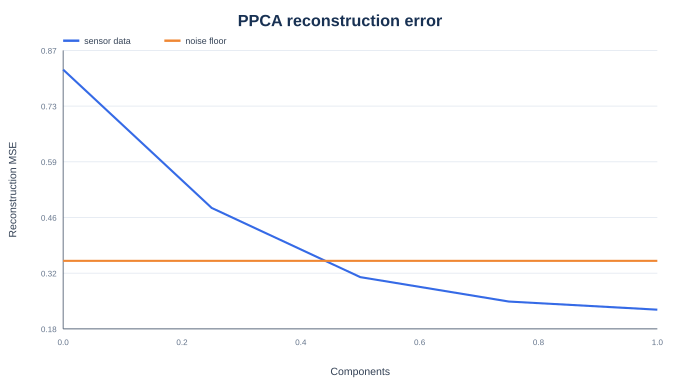

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# PPCA: z~N(0,I), x=Wz+mu+epsilon, epsilon~N(0,sigma^2 I).
rng=np.random.default_rng(20)
z=rng.normal(size=(500,2))
W=np.array([[2.,.2],[1.5,.1],[.1,1.8],[.2,1.4],[.9,.8]])
mu=np.array([20.,3.,101.,12.,45.])
X=z@W.T+mu+rng.normal(0,.35,(500,5))
X[rng.random(X.shape)<.03]=np.nan
columns=["temperature","vibration","pressure","current","humidity"]
df=pd.DataFrame(X,columns=columns)
X=SimpleImputer(strategy="median").fit_transform(df)
mean=X.mean(axis=0);Xc=X-mean
pca2=PCA(n_components=2).fit(X)
print(f"Estimated isotropic noise variance sigma²: {pca2.noise_variance_:.4f}")
errors=[]
for k in range(1,6):
    pca=PCA(n_components=k).fit(X)
    reconstructed=pca.inverse_transform(pca.transform(X))
    errors.append(np.mean((X-reconstructed)**2))
print("Reconstruction MSE by components:",np.round(errors,4))
plt.plot(range(1,6),errors,"o-");plt.xlabel("Components");plt.ylabel("Reconstruction MSE")
plt.title("PPCA/PCA reconstruction error");plt.grid(alpha=.2);plt.show()

# Approximate PPCA sampling with the first two principal directions and residual noise.
k=2; basis=pca2.components_.T
latent=rng.normal(size=(8,k))
generated=(latent*np.sqrt(pca2.explained_variance_))@basis.T+mean
generated+=rng.normal(0,np.sqrt(pca2.noise_variance_),generated.shape)
print("Generated sensor samples:\n",pd.DataFrame(generated,columns=columns).round(2))